# Problem 2: Transformers & Causal Language Models
This notebook implements scaled dot-product attention, multi-head attention, positional encoding, transformer encoder block, HAR Transformer Classifier, and causal language modeling on Tiny Shakespeare.

In [1]:
import os
import math
import random
import time
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'problem2' else os.getcwd()
FIGURE_DIR = os.path.join(PROJECT_ROOT, 'problem2', 'figures')
os.makedirs(FIGURE_DIR, exist_ok=True)

def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
results_path=os.path.join(PROJECT_ROOT,'results.csv')
results_cols=['problem','model','seed','seq_len','test_acc','macro_f1','test_mse','params','sec_per_epoch','val_loss_nats','bits_per_char','notes']
def append_results(rows):
    base=pd.read_csv(results_path) if os.path.exists(results_path) else pd.DataFrame(columns=results_cols)
    pd.concat([base,pd.DataFrame(rows)],ignore_index=True).to_csv(results_path,index=False)


## 1. Custom Scaled Dot Product Attention

In [2]:
class ScaledDotProductAttention(nn.Module):
    def __init__(self, dropout: float = 0.0):
        super().__init__()
        self.dropout = nn.Dropout(dropout)

    def forward(self, q: torch.Tensor, k: torch.Tensor, v: torch.Tensor, mask: torch.Tensor = None) -> tuple:
        d_k = q.size(-1)
        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(d_k)
        if mask is not None:
            scores = scores.masked_fill(mask == 0, float('-inf'))
        attn_probs = F.softmax(scores, dim=-1)
        attn_probs = self.dropout(attn_probs)
        return torch.matmul(attn_probs, v), attn_probs

print('Attention Layer Defined successfully!')

Attention Layer Defined successfully!


## 2. Multi-Head Attention

In [3]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model: int, num_heads: int, dropout: float = 0.0):
        super().__init__()
        assert d_model % num_heads == 0
        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads

        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        self.attention = ScaledDotProductAttention(dropout)

    def forward(self, q: torch.Tensor, k: torch.Tensor, v: torch.Tensor, mask: torch.Tensor = None) -> torch.Tensor:
        batch_size = q.size(0)
        q_p = self.W_q(q).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        k_p = self.W_k(k).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        v_p = self.W_v(v).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)

        if mask is not None and mask.dim() == 3:
            mask = mask.unsqueeze(1)

        out, attn_probs = self.attention(q_p, k_p, v_p, mask)
        out = out.transpose(1, 2).contiguous().view(batch_size, -1, self.d_model)
        return self.W_o(out)

## 3. Positional Encoding

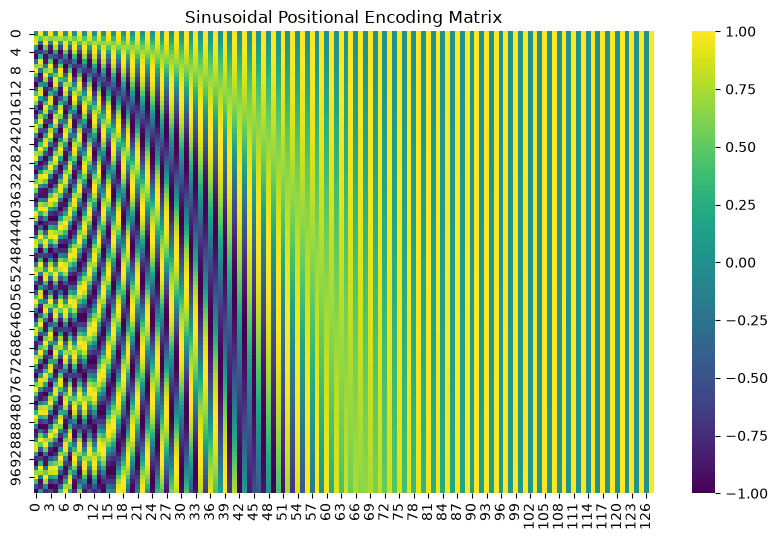

In [4]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model: int, max_len: int = 5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x + self.pe[:, :x.size(1)]

pe_module = PositionalEncoding(128, 100)
plt.figure(figsize=(10, 6))
sns.heatmap(pe_module.pe[0].cpu().numpy(), cmap='viridis')
plt.title('Sinusoidal Positional Encoding Matrix')
plt.savefig(os.path.join(FIGURE_DIR, 'positional_encoding.png'))
plt.show()

## 4. Transformer Encoder Block

In [5]:
class TransformerEncoderBlock(nn.Module):
    def __init__(self, d_model: int, num_heads: int, d_ff: int, dropout: float = 0.1):
        super().__init__()
        self.mha = MultiHeadAttention(d_model, num_heads, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model)
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor, mask: torch.Tensor = None) -> torch.Tensor:
        norm_x = self.norm1(x)
        attn_out = self.mha(norm_x, norm_x, norm_x, mask)
        x = x + self.dropout(attn_out)
        norm_x2 = self.norm2(x)
        ffn_out = self.ffn(norm_x2)
        x = x + self.dropout(ffn_out)
        return x

## TASK 1: Attention Tests and Hand-Checkable Example
The following tests verify probability normalisation, equivalence with PyTorch's scaled-dot-product attention, and causal masking. The small three-token example prints the scores, softmax weights, and output for manual checking.


In [1]:
# Unit tests for the custom scaled dot-product attention.
torch.manual_seed(7)
attention = ScaledDotProductAttention(dropout=0.0).eval()
q = torch.randn(2, 4, 8); k = torch.randn(2, 4, 8); v = torch.randn(2, 4, 8)
out, weights = attention(q, k, v)
assert torch.allclose(weights.sum(dim=-1), torch.ones_like(weights.sum(dim=-1)), atol=1e-6)
reference = F.scaled_dot_product_attention(q, k, v, dropout_p=0.0)
assert torch.allclose(out, reference, atol=1e-5)
causal_mask = torch.tril(torch.ones(4, 4, dtype=torch.bool))
_, causal_weights = attention(q, k, v, causal_mask)
assert torch.allclose(causal_weights.masked_select(~causal_mask.unsqueeze(0)), torch.zeros_like(causal_weights.masked_select(~causal_mask.unsqueeze(0))), atol=1e-7)
print('Attention tests passed: row sums, PyTorch match, and causal zeros.')

# Three-token hand-checkable example: d_k=2 and no mask.
q3 = torch.tensor([[[1., 0.], [0., 2.], [1., 1.]]])
k3 = torch.tensor([[[0., 1.], [1., 1.], [2., 0.]]])
v3 = torch.tensor([[[10., 0.], [0., 20.], [5., 5.]]])
out3, w3 = attention(q3, k3, v3)
print('Scores / sqrt(2):\n', (q3 @ k3.transpose(-2,-1) / math.sqrt(2))[0])
print('Softmax weights:\n', w3[0])
print('Output:\n', out3[0])


Attention tests passed: row sums, PyTorch match, and causal zeros.
Scores / sqrt(2):
 tensor([[0.0000, 0.7071, 1.4142],
        [1.4142, 1.4142, 0.0000],
        [0.7071, 1.4142, 1.4142]])
Softmax weights:
 tensor([[0.1400, 0.2840, 0.5760],
        [0.4458, 0.4458, 0.1084],
        [0.1978, 0.4011, 0.4011]])
Output:
 tensor([[ 4.2802,  8.5598],
        [ 5.0000,  9.4581],
        [ 3.9833, 10.0278]])


## TASK 2: Encoder Block Parameter Count
For one block, the weight matrices contribute 4d? in multi-head attention and 2?d?d_ff in the feed-forward network. Biases and two LayerNorms explain the difference from `sum(p.numel())`.


In [7]:
d_model, d_ff = 128, 512
block = TransformerEncoderBlock(d_model, num_heads=4, d_ff=d_ff, dropout=0.0)
weight_only = 4*d_model*d_model + 2*d_model*d_ff
actual = sum(p.numel() for p in block.parameters())
biases = 4*d_model + d_ff + d_model
layer_norm = 4*d_model  # gamma and beta for two LayerNorms
assert weight_only == 196_608
assert actual == weight_only + biases + layer_norm
print(f'Weights only: {weight_only:,}; biases: {biases:,}; LayerNorm parameters: {layer_norm:,}; total: {actual:,}')


Weights only: 196,608; biases: 1,152; LayerNorm parameters: 512; total: 198,272


## TASK 3: HAR Transformer Classifier
This loads the same 128-step, 9-channel HAR data used in Problem 1, with a subject-wise validation split and training-only normalisation. It prepends a CLS token and supports no positional encoding, fixed sinusoidal encoding, and learned positional embeddings.


In [8]:
# Load UCI HAR, downloading it into this notebook runtime when it is not already present.
def load_har_subset(har_dir, subset):
    names = ['body_acc_x_', 'body_acc_y_', 'body_acc_z_', 'body_gyro_x_', 'body_gyro_y_', 'body_gyro_z_', 'total_acc_x_', 'total_acc_y_', 'total_acc_z_']
    signals = [np.loadtxt(os.path.join(har_dir, subset, 'Inertial Signals', f'{name}{subset}.txt'), dtype=np.float32) for name in names]
    x = np.transpose(np.stack(signals), (1, 2, 0))
    y = np.loadtxt(os.path.join(har_dir, subset, f'y_{subset}.txt'), dtype=np.int64) - 1
    subjects = np.loadtxt(os.path.join(har_dir, subset, f'subject_{subset}.txt'), dtype=np.int64)
    return x, y, subjects

har_dir = os.path.join(PROJECT_ROOT, 'UCI_HAR', 'UCI HAR Dataset')
if not os.path.isdir(har_dir):
    har_zip_path = os.path.join(PROJECT_ROOT, 'human_activity_recognition.zip')
    har_url = 'https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip'
    if not os.path.exists(har_zip_path):
        print('Downloading UCI HAR for this Problem 2 runtime...')
        urllib.request.urlretrieve(har_url, har_zip_path)
    extracted_root = os.path.join(PROJECT_ROOT, 'UCI_HAR_extracted')
    os.makedirs(extracted_root, exist_ok=True)
    with zipfile.ZipFile(har_zip_path, 'r') as archive:
        archive.extractall(extracted_root)
    inner_zip = os.path.join(extracted_root, 'UCI HAR Dataset.zip')
    if not os.path.isfile(inner_zip):
        raise FileNotFoundError('UCI HAR archive did not contain the expected nested dataset: ' + inner_zip)
    har_root = os.path.join(PROJECT_ROOT, 'UCI_HAR')
    os.makedirs(har_root, exist_ok=True)
    with zipfile.ZipFile(inner_zip, 'r') as archive:
        archive.extractall(har_root)
if not os.path.isdir(har_dir):
    raise FileNotFoundError('UCI HAR extraction did not create the expected directory: ' + har_dir)
x_raw, y_raw, subjects = load_har_subset(har_dir, 'train')
X_test_har, y_test_har, _ = load_har_subset(har_dir, 'test')
# Draw four validation subjects from the 21 training subjects for the experiment seed.
val_mask = np.isin(subjects, np.random.default_rng(1).choice(np.unique(subjects), 4, replace=False))
X_train_har, y_train_har = x_raw[~val_mask], y_raw[~val_mask]
X_val_har, y_val_har = x_raw[val_mask], y_raw[val_mask]
channel_mean = X_train_har.mean(axis=(0,1)); channel_std = X_train_har.std(axis=(0,1)).clip(1e-8)
X_train_har = (X_train_har-channel_mean)/channel_std
X_val_har = (X_val_har-channel_mean)/channel_std
X_test_har = (X_test_har-channel_mean)/channel_std
print('HAR:', X_train_har.shape, X_val_har.shape, X_test_har.shape)

class HARData(Dataset):
    def __init__(self, x, y): self.x=torch.as_tensor(x,dtype=torch.float32); self.y=torch.as_tensor(y,dtype=torch.long)
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.x[i], self.y[i]


HAR: (5905, 128, 9) (1447, 128, 9) (2947, 128, 9)


In [9]:
class HARTransformerClassifier(nn.Module):
    def __init__(self, positional='sinusoidal', d_model=128, heads=4, layers=2, dropout=0.1):
        super().__init__(); self.positional=positional
        self.embed=nn.Linear(9,d_model); self.cls=nn.Parameter(torch.zeros(1,1,d_model))
        self.fixed_pos=PositionalEncoding(d_model,129) if positional=='sinusoidal' else None
        self.learned_pos=nn.Embedding(129,d_model) if positional=='learned' else None
        self.blocks=nn.ModuleList([TransformerEncoderBlock(d_model,heads,4*d_model,dropout) for _ in range(layers)])
        self.norm=nn.LayerNorm(d_model); self.head=nn.Linear(d_model,6)
    def forward(self,x):
        b=x.size(0); x=self.embed(x); x=torch.cat([self.cls.expand(b,-1,-1),x],dim=1)
        if self.fixed_pos is not None: x=self.fixed_pos(x)
        elif self.learned_pos is not None: x=x+self.learned_pos(torch.arange(x.size(1),device=x.device))[None]
        for block in self.blocks: x=block(x)
        return self.head(self.norm(x[:,0]))

def train_har_transformer(positional, epochs=10, seed=1, batch_size=128):
    seed_everything(seed); model=HARTransformerClassifier(positional).to(device)
    # Rebuild the subject-wise validation split for this seed; training data remain normalised with their own statistics.
    mask=np.isin(subjects,np.random.default_rng(seed).choice(np.unique(subjects),4,replace=False)); raw_train=x_raw[~mask]; mean=raw_train.mean(axis=(0,1)); std=raw_train.std(axis=(0,1)).clip(1e-8)
    train=DataLoader(HARData((raw_train-mean)/std,y_raw[~mask]),batch_size=batch_size,shuffle=True)
    test=DataLoader(HARData((X_test_har*channel_std+channel_mean-mean)/std,y_test_har),batch_size=batch_size)
    opt=torch.optim.Adam(model.parameters(),lr=1e-3); loss_fn=nn.CrossEntropyLoss(); start=time.perf_counter()
    for _ in range(epochs):
        model.train()
        for xb,yb in train:
            opt.zero_grad(set_to_none=True); loss_fn(model(xb.to(device)),yb.to(device)).backward(); opt.step()
    seconds=(time.perf_counter()-start)/epochs; model.eval(); pred=[]; truth=[]
    with torch.no_grad():
        for xb,yb in test: pred.extend(model(xb.to(device)).argmax(1).cpu().tolist()); truth.extend(yb.tolist())
    return {'positional':positional,'seed':seed,'accuracy':accuracy_score(truth,pred),'params':sum(p.numel() for p in model.parameters()),'seconds_per_epoch':seconds}


In [10]:
# Positional-information ablation. Run this cell after choosing a common epoch budget.
HAR_EPOCHS = 10
har_transformer_results = [train_har_transformer(kind, HAR_EPOCHS, seed) for kind in ['none','sinusoidal','learned'] for seed in [1,2,3]]
append_results([{'problem':'problem2','model':'HAR_transformer_'+r['positional'],'seed':r['seed'],'seq_len':128,'test_acc':r['accuracy'],'macro_f1':np.nan,'test_mse':np.nan,'params':r['params'],'sec_per_epoch':r['seconds_per_epoch'],'val_loss_nats':np.nan,'bits_per_char':np.nan,'notes':'CLS HAR'} for r in har_transformer_results])
pd.DataFrame(har_transformer_results).groupby('positional')[['accuracy','params','seconds_per_epoch']].agg(['mean','std'])
# Compare this table with the best Problem 1 model's accuracy, parameters, and seconds per epoch.


accuracy              params      seconds_per_epoch          
                mean       std      mean  std              mean       std
positional                                                               
learned     0.891528  0.009195  415494.0  0.0         88.963332  5.523007
none        0.885081  0.017649  398982.0  0.0         78.274560  1.549213
sinusoidal  0.881688  0.010074  398982.0  0.0         77.395873  0.356475

## TASK 4: Character-Level Causal Language Model
The model uses context 128, d=128, four heads, and four causal encoder blocks. It records validation loss in nats and bits per character, then generates 500 characters at three temperatures with top-k sampling.


In [11]:
# Download Tiny Shakespeare once, then create a fixed 90/10 split.
text_path=os.path.join(PROJECT_ROOT,'tinyshakespeare.txt')
if not os.path.exists(text_path): urllib.request.urlretrieve('https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt',text_path)
text=open(text_path,encoding='utf-8').read(); chars=sorted(set(text)); vocab_size=len(chars)
stoi={c:i for i,c in enumerate(chars)}; itos={i:c for c,i in stoi.items()}
tokens=torch.tensor([stoi[c] for c in text],dtype=torch.long); split=int(.9*len(tokens)); train_tokens,val_tokens=tokens[:split],tokens[split:]
print(f'Tiny Shakespeare: {len(text):,} characters, vocabulary={vocab_size}')

class CharDataset(Dataset):
    def __init__(self, tokens, context=128): self.tokens=tokens; self.context=context
    def __len__(self): return len(self.tokens)-self.context
    def __getitem__(self,i): return self.tokens[i:i+self.context], self.tokens[i+1:i+self.context+1]


Tiny Shakespeare: 1,115,394 characters, vocabulary=65


In [12]:
class CausalTransformerLM(nn.Module):
    def __init__(self, vocab_size, context=128, d_model=128, heads=4, layers=4, dropout=.1, causal=True):
        super().__init__(); self.context=context; self.causal=causal
        self.token_embed=nn.Embedding(vocab_size,d_model); self.pos_embed=nn.Embedding(context,d_model)
        self.blocks=nn.ModuleList([TransformerEncoderBlock(d_model,heads,4*d_model,dropout) for _ in range(layers)])
        self.norm=nn.LayerNorm(d_model); self.lm_head=nn.Linear(d_model,vocab_size)
    def forward(self, idx):
        b,t=idx.shape
        if t>self.context: raise ValueError('input exceeds context length')
        x=self.token_embed(idx)+self.pos_embed(torch.arange(t,device=idx.device))[None]
        mask=torch.tril(torch.ones(t,t,dtype=torch.bool,device=idx.device)) if self.causal else None
        for block in self.blocks: x=block(x,mask)
        return self.lm_head(self.norm(x))

def language_loss(model, loader, limit=None):
    model.eval(); total=count=0
    with torch.no_grad():
        for step,(xb,yb) in enumerate(loader):
            logits=model(xb.to(device)); total+=F.cross_entropy(logits.reshape(-1,vocab_size),yb.to(device).reshape(-1),reduction='sum').item(); count+=yb.numel()
            if limit is not None and step+1>=limit: break
    return total/count

def train_lm(causal=True, heads=4, context=128, epochs=5, max_batches=200, seed=1):
    seed_everything(seed); model=CausalTransformerLM(vocab_size,context,128,heads,4,causal=causal).to(device)
    train=DataLoader(CharDataset(train_tokens,context),batch_size=32,shuffle=True); val=DataLoader(CharDataset(val_tokens,context),batch_size=32)
    opt=torch.optim.Adam(model.parameters(),lr=3e-4); history=[]
    for epoch in range(epochs):
        model.train()
        for step,(xb,yb) in enumerate(train):
            opt.zero_grad(set_to_none=True); logits=model(xb.to(device)); loss=F.cross_entropy(logits.reshape(-1,vocab_size),yb.to(device).reshape(-1)); loss.backward(); opt.step()
            if step+1>=max_batches: break
        val_loss=language_loss(model,val,limit=100); history.append(val_loss); print(f'epoch {epoch+1}: val={val_loss:.3f} nats, {val_loss/math.log(2):.3f} bpc')
    return model, history

def generate(model, prompt='ROMEO:', length=500, temperature=.8, top_k=20):
    model.eval(); ids=torch.tensor([[stoi[c] for c in prompt]],device=device)
    with torch.no_grad():
        for _ in range(length):
            logits=model(ids[:,-model.context:])[:,-1]/temperature
            values,indices=torch.topk(logits,min(top_k,vocab_size)); probs=F.softmax(values,dim=-1)
            next_id=indices.gather(-1,torch.multinomial(probs,1)); ids=torch.cat([ids,next_id],dim=1)
    return ''.join(itos[i] for i in ids[0].tolist())


In [13]:
# Main causal-LM training and required temperature samples.
LM_EPOCHS, MAX_BATCHES = 5, 200
lm_model, lm_history = train_lm(causal=True,heads=4,context=128,epochs=LM_EPOCHS,max_batches=MAX_BATCHES)
final_val_loss=lm_history[-1]; print('Final validation loss:',final_val_loss,'nats; BPC:',final_val_loss/math.log(2))
append_results([{'problem':'problem2','model':'causal_transformer','seed':1,'seq_len':128,'test_acc':np.nan,'macro_f1':np.nan,'test_mse':np.nan,'params':sum(p.numel() for p in lm_model.parameters()),'sec_per_epoch':np.nan,'val_loss_nats':final_val_loss,'bits_per_char':final_val_loss/math.log(2),'notes':'Tiny Shakespeare'}])
with open(os.path.join(PROJECT_ROOT,'generated_samples.txt'),'w',encoding='utf-8') as samples_file:
    samples_file.write('')
for temp in [0.2,0.8,1.5]:
    sample=generate(lm_model,temperature=temp,top_k=20,length=500)
    open(os.path.join(PROJECT_ROOT,f'generated_temp_{temp}.txt'),'w',encoding='utf-8').write(sample)
    with open(os.path.join(PROJECT_ROOT,'generated_samples.txt'),'a',encoding='utf-8') as samples_file: samples_file.write(f'\n\nTemperature {temp}\n{sample}\n')
    print(f'\nTemperature {temp}:\n{sample[:500]}')


epoch 1: val=2.563 nats, 3.697 bpc
epoch 2: val=2.488 nats, 3.590 bpc
epoch 3: val=2.413 nats, 3.482 bpc
epoch 4: val=2.302 nats, 3.321 bpc
epoch 5: val=2.202 nats, 3.176 bpc
Final validation loss: 2.201751658916473 nats; BPC: 3.1764561995878444

Temperature 0.2:
ROMEO:
I the the the seat the the the the the the ther the bere there ther and
And the the she the my the the and the the the there the the shereand
The the sher the the spreat the and the and there ber thererean the ther
The that she han the the the ther and and the the the and there the the thereathe
The the there ber the the the the there spereat the and deare therer
Thand the the mathe be and an the there the the there there the and
The the the the ther she for ther there the the there she a

Temperature 0.8:
ROMEO:
Noused inhth ut wingner her frerevelind un,
Whin sadithat wicth sove me therep sharer;
The wit go whamave yord e singhastige bo dor
What he there bechmadran matth fren moughthe cer matre
nerend ad there in hong

## TASK 5: Attention Visualisation and Ablations
These cells create two head heatmaps, compare 1/4/8 heads at fixed d, compare causal masking against no mask, and measure context-length time and memory. Run them after the main language-model cell.


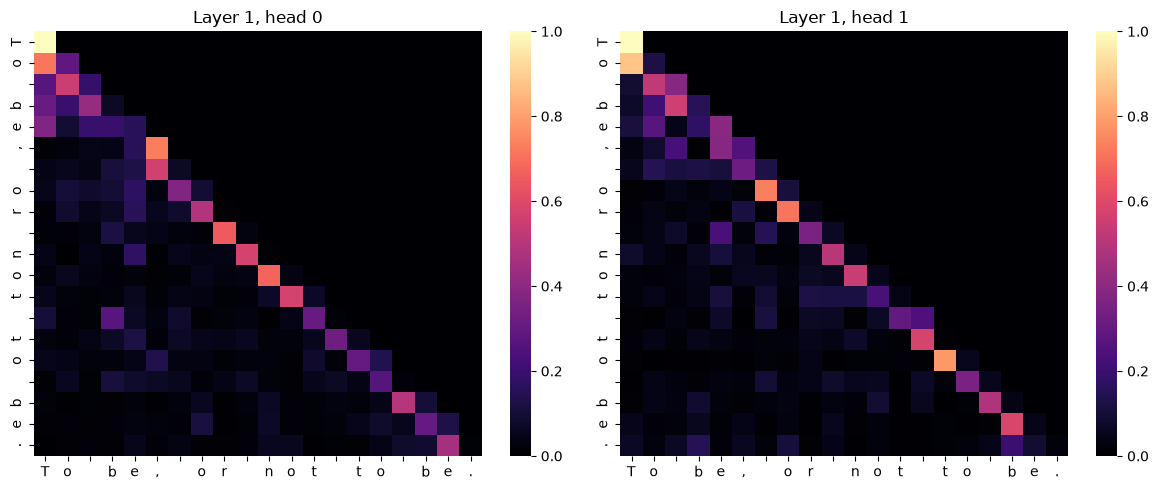

In [14]:
# Heatmaps for heads 0 and 1 on one short sentence.
sentence='To be, or not to be.'
ids=torch.tensor([[stoi.get(c,stoi[' ']) for c in sentence]],device=device)
with torch.no_grad():
    x=lm_model.token_embed(ids)+lm_model.pos_embed(torch.arange(ids.size(1),device=device))[None]
    first=lm_model.blocks[0]; nx=first.norm1(x); b,t,_=nx.shape
    q=first.mha.W_q(nx).view(b,t,first.mha.num_heads,first.mha.d_k).transpose(1,2)
    k=first.mha.W_k(nx).view(b,t,first.mha.num_heads,first.mha.d_k).transpose(1,2)
    mask=torch.tril(torch.ones(t,t,dtype=torch.bool,device=device)); _,head_weights=first.mha.attention(q,k,q,mask)
fig,ax=plt.subplots(1,2,figsize=(12,5))
for h in [0,1]:
    sns.heatmap(head_weights[0,h].cpu(),ax=ax[h],cmap='magma',xticklabels=list(sentence),yticklabels=list(sentence)); ax[h].set_title(f'Layer 1, head {h}')
plt.tight_layout(); plt.savefig(os.path.join(FIGURE_DIR,'attention_heads.png'),dpi=160); plt.show()


In [15]:
# Head-count ablation at fixed d=128. Keep the epoch and batch budget identical.
head_results=[]
for heads in [1,4,8]:
    model,history=train_lm(causal=True,heads=heads,context=128,epochs=LM_EPOCHS,max_batches=MAX_BATCHES,seed=1)
    head_results.append({'heads':heads,'val_loss_nats':history[-1],'bits_per_char':history[-1]/math.log(2),'params':sum(p.numel() for p in model.parameters())})
pd.DataFrame(head_results)


epoch 1: val=2.563 nats, 3.698 bpc
epoch 2: val=2.472 nats, 3.566 bpc
epoch 3: val=2.321 nats, 3.348 bpc
epoch 4: val=2.191 nats, 3.161 bpc
epoch 5: val=2.121 nats, 3.060 bpc
epoch 1: val=2.563 nats, 3.697 bpc
epoch 2: val=2.488 nats, 3.590 bpc
epoch 3: val=2.413 nats, 3.482 bpc
epoch 4: val=2.302 nats, 3.321 bpc
epoch 5: val=2.202 nats, 3.176 bpc
epoch 1: val=2.565 nats, 3.701 bpc
epoch 2: val=2.480 nats, 3.578 bpc
epoch 3: val=2.422 nats, 3.494 bpc
epoch 4: val=2.333 nats, 3.365 bpc
epoch 5: val=2.244 nats, 3.238 bpc


,heads,val_loss_nats,bits_per_char,params
0,1,2.120888,3.059794,826433
1,4,2.201752,3.176456,826433
2,8,2.244366,3.237935,826433


epoch 1: val=2.575 nats, 3.715 bpc
epoch 2: val=2.496 nats, 3.600 bpc
epoch 3: val=2.401 nats, 3.465 bpc
epoch 4: val=2.284 nats, 3.295 bpc
epoch 5: val=2.187 nats, 3.155 bpc
epoch 1: val=2.566 nats, 3.703 bpc
epoch 2: val=1.558 nats, 2.247 bpc
epoch 3: val=0.070 nats, 0.101 bpc
epoch 4: val=0.030 nats, 0.044 bpc
epoch 5: val=0.025 nats, 0.036 bpc


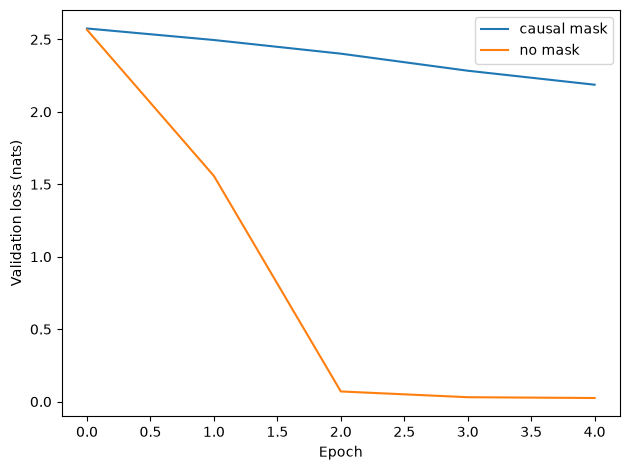

No-mask generation:
 ROMEO:RRORR:ROMR:RMRRORRRRRRRRIRRRRR:RRRRRRRRR::RR:RRR:RIRRRRRRR:RR:XRRRRRRR:RRIRRRRRRRRRRRRRRRRRRRRRRRR:RRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRoRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRRR


In [16]:
# Causal-mask ablation: no-mask training can reduce teacher-forced loss by looking ahead,
# but autoregressive generation has no future characters and becomes inconsistent.
masked_model,masked_history=train_lm(causal=True,heads=4,context=128,epochs=LM_EPOCHS,max_batches=MAX_BATCHES,seed=2)
unmasked_model,unmasked_history=train_lm(causal=False,heads=4,context=128,epochs=LM_EPOCHS,max_batches=MAX_BATCHES,seed=2)
plt.plot(masked_history,label='causal mask'); plt.plot(unmasked_history,label='no mask'); plt.xlabel('Epoch'); plt.ylabel('Validation loss (nats)'); plt.legend(); plt.tight_layout(); plt.savefig(os.path.join(FIGURE_DIR,'causal_mask_ablation.png'),dpi=160); plt.show()
print('No-mask generation:\n',generate(unmasked_model,temperature=.8,length=500))


In [ ]:
# Measure wall time and process-resident memory growth for one forward/backward step.
# The host RSS delta is sampled during the step so CPU runs still produce a memory curve.
import threading
import psutil

process = psutil.Process(os.getpid())
def measure_step_peak_rss(step_fn, sample_interval=0.005):
    baseline = process.memory_info().rss
    peak = [baseline]
    stop_sampling = threading.Event()
    def sample_rss():
        while not stop_sampling.wait(sample_interval):
            peak[0] = max(peak[0], process.memory_info().rss)
    sampler = threading.Thread(target=sample_rss, daemon=True)
    sampler.start()
    try:
        start = time.perf_counter()
        step_fn()
        elapsed = time.perf_counter() - start
    finally:
        stop_sampling.set()
        sampler.join()
    peak[0] = max(peak[0], process.memory_info().rss)
    return elapsed, max(0.0, (peak[0] - baseline) / 1024**2)

context_results=[]
for context in [64,128,256,512]:
    model=CausalTransformerLM(vocab_size,context,128,4,4).to(device)
    xb=torch.randint(vocab_size,(4,context),device=device)
    yb=torch.randint(vocab_size,(4,context),device=device)
    if device.type=='cuda': torch.cuda.reset_peak_memory_stats()
    def forward_backward():
        model.zero_grad(set_to_none=True)
        logits=model(xb)
        F.cross_entropy(logits.reshape(-1,vocab_size),yb.reshape(-1)).backward()
    elapsed, host_rss_delta_mb = measure_step_peak_rss(forward_backward)
    cuda_peak_mb = torch.cuda.max_memory_allocated()/1024**2 if device.type=='cuda' else np.nan
    context_results.append({'context':context,'seconds_per_step':elapsed,
        'host_peak_rss_delta_mb':host_rss_delta_mb,'peak_cuda_memory_mb':cuda_peak_mb})
context_scaling_df=pd.DataFrame(context_results)
display(context_scaling_df)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(context_scaling_df['context'],context_scaling_df['seconds_per_step'],marker='o')
axes[0].set(xlabel='Context length',ylabel='Forward/backward seconds per step',title='Runtime')
axes[1].plot(context_scaling_df['context'],context_scaling_df['host_peak_rss_delta_mb'],marker='o',label='Host RSS increase')
axes[1].set(xlabel='Context length',ylabel='Peak host RSS increase (MB)',title='Memory')
axes[1].legend(); fig.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR,'context_scaling.png'),dpi=160); plt.show()


## Analysis Notes
Use the generated tables and figures in the report: explain the two attention-head heatmaps, compare positional encodings on HAR, describe low/medium/high-temperature samples, explain why no-mask loss is invalid for generation, and relate the context benchmark to O(n??d). Include the best Problem 1 HAR result alongside the Transformer HAR table.
